# Lab 3B — From vibration signals to spectral features

**Audience:** beginner Strategic Engineering MSc students  
**Scope:** Lecture 3, slides 69–95  
**Estimated time:** 60–75 min — teacher solution

## Scenario
A rotating machine is monitored by a vibration sensor sampled at **100 Hz**. We will work with short synthetic vibration windows representing two operating conditions:

- **normal:** a dominant rotational component around 10 Hz with weak harmonics;
- **fault-like:** the same main rotation plus stronger harmonics and more high-frequency energy.

The goal is **not** to build a sophisticated classifier. The goal is to learn how a time signal becomes a frequency-domain representation and how to construct interpretable spectral features that could later be used by a conventional ML model.

## Learning objectives
By the end of the lab you should be able to:

1. relate sampling frequency, sampling interval and Nyquist frequency;
2. compute and interpret a one-sided FFT spectrum;
3. connect window duration to frequency resolution;
4. extract dominant-frequency and band-power features;
5. explain spectral leakage and the role of a Hann window;
6. combine time-domain and frequency-domain features into a feature table;
7. recognize what information manual features preserve and what they can discard.


## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

FS = 100.0               # Hz
DT = 1.0 / FS            # seconds
WINDOW_SECONDS = 4.0
N = int(FS * WINDOW_SECONDS)
t = np.arange(N) / FS

print(f"Sampling frequency: {FS:.0f} Hz")
print(f"Sampling interval: {DT:.3f} s")
print(f"Frames per window: {N}")
print(f"Window duration: {N/FS:.1f} s")


Sampling frequency: 100 Hz
Sampling interval: 0.010 s
Frames per window: 400
Window duration: 4.0 s


In [2]:
def make_vibration_window(condition, rng, fs=FS, n=N):
    # Create one synthetic vibration window for teaching purposes.
    time = np.arange(n) / fs

    # Slight run-to-run variability
    f0 = rng.normal(10.0, 0.20)
    amp = rng.normal(1.0, 0.08)
    phase = rng.uniform(0, 2*np.pi)

    x = amp * np.sin(2*np.pi*f0*time + phase)

    if condition == "normal":
        x += 0.12 * np.sin(2*np.pi*(2*f0)*time + 0.3)
        x += 0.05 * np.sin(2*np.pi*35.0*time + 1.0)
        noise = 0.18
    elif condition == "fault-like":
        # Stronger harmonics and more high-frequency content.
        x += 0.38 * np.sin(2*np.pi*(2*f0)*time + 0.3)
        x += 0.25 * np.sin(2*np.pi*(3*f0)*time + 0.8)
        x += 0.20 * np.sin(2*np.pi*35.0*time + 1.0)
        noise = 0.22
    else:
        raise ValueError("condition must be 'normal' or 'fault-like'")

    # Add a small DC offset that varies by recording.
    x += rng.normal(0.15, 0.04)
    x += rng.normal(0.0, noise, size=n)
    return x

records = []
for condition in ["normal", "fault-like"]:
    for i in range(60):
        records.append({
            "condition": condition,
            "window_id": f"{condition}_{i:02d}",
            "signal": make_vibration_window(condition, rng),
        })

print(f"Generated {len(records)} windows.")


Generated 120 windows.


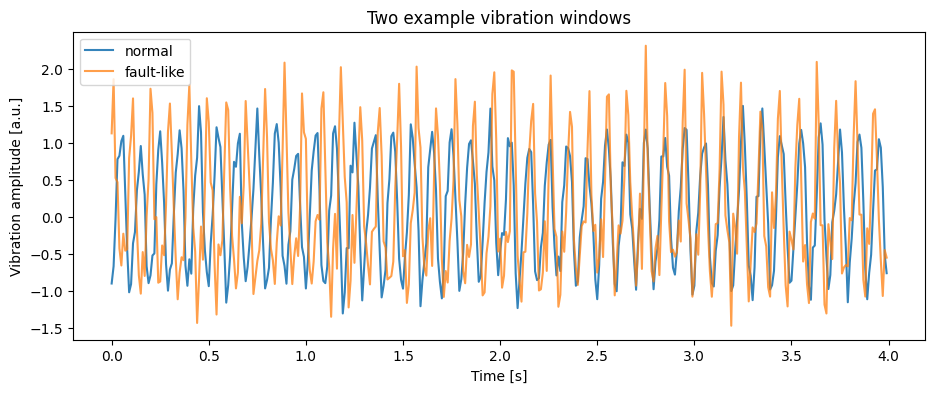

In [3]:
normal = next(r["signal"] for r in records if r["condition"] == "normal")
fault = next(r["signal"] for r in records if r["condition"] == "fault-like")

plt.figure(figsize=(11, 4))
plt.plot(t, normal, label="normal", alpha=0.9)
plt.plot(t, fault, label="fault-like", alpha=0.75)
plt.xlabel("Time [s]")
plt.ylabel("Vibration amplitude [a.u.]")
plt.title("Two example vibration windows")
plt.legend()
plt.show()


## 1. Sampling frequency and Nyquist limit

In [4]:
sampling_interval = 1.0 / FS
nyquist = FS / 2.0

print("Sampling interval [s] =", sampling_interval)
print("Nyquist frequency [Hz] =", nyquist)
print("A 65 Hz component is above Nyquist and will alias to a lower frequency.")


Sampling interval [s] = 0.01
Nyquist frequency [Hz] = 50.0
A 65 Hz component is above Nyquist and will alias to a lower frequency.


For Fs = 100 Hz, Δt = 0.01 s and the Nyquist frequency is 50 Hz. A 65 Hz component cannot be uniquely represented; after sampling it aliases into the observable frequency range.

## 2. From time domain to frequency domain

In [5]:
def power_spectrum(x, fs=FS, apply_hann=False):
    x = np.asarray(x)
    x = x - np.mean(x)
    if apply_hann:
        x = x * np.hanning(len(x))
    X = np.fft.rfft(x)
    power = np.abs(X) ** 2
    freq = np.fft.rfftfreq(len(x), d=1.0/fs)
    return freq, power

freq_n, power_n = power_spectrum(normal)
freq_f, power_f = power_spectrum(fault)


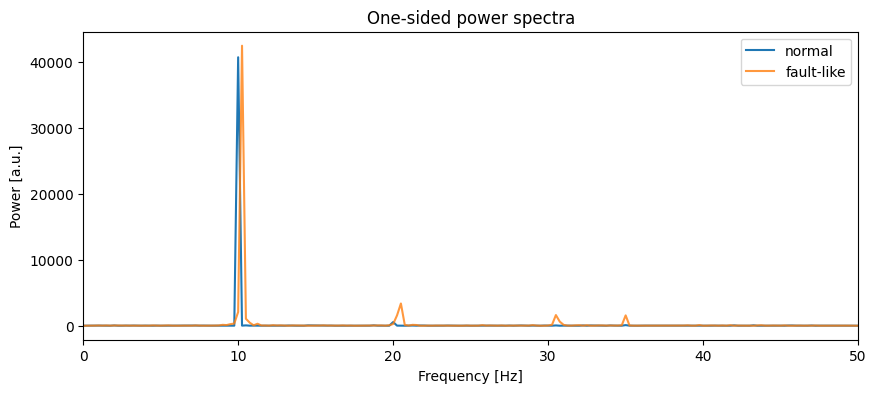

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(freq_n, power_n, label="normal")
plt.plot(freq_f, power_f, label="fault-like", alpha=0.8)
plt.xlim(0, FS/2)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [a.u.]")
plt.title("One-sided power spectra")
plt.legend()
plt.show()


The main peak is around 10 Hz. The fault-like signal has stronger harmonic/high-frequency content, especially around roughly 20, 30 and 35 Hz.

## 3. Dominant frequency

In [7]:
def dominant_frequency(x, fs=FS):
    freq, power = power_spectrum(x, fs)
    idx = 1 + np.argmax(power[1:])
    return freq[idx]

print("Normal dominant frequency:", dominant_frequency(normal), "Hz")
print("Fault-like dominant frequency:", dominant_frequency(fault), "Hz")


Normal dominant frequency: 10.0 Hz
Fault-like dominant frequency: 10.25 Hz


## 4. Frequency resolution and window duration

In [8]:
resolution_1s = FS / int(FS * 1.0)
resolution_4s = FS / int(FS * 4.0)
print("1 s window resolution:", resolution_1s, "Hz")
print("4 s window resolution:", resolution_4s, "Hz")


1 s window resolution: 1.0 Hz
4 s window resolution: 0.25 Hz


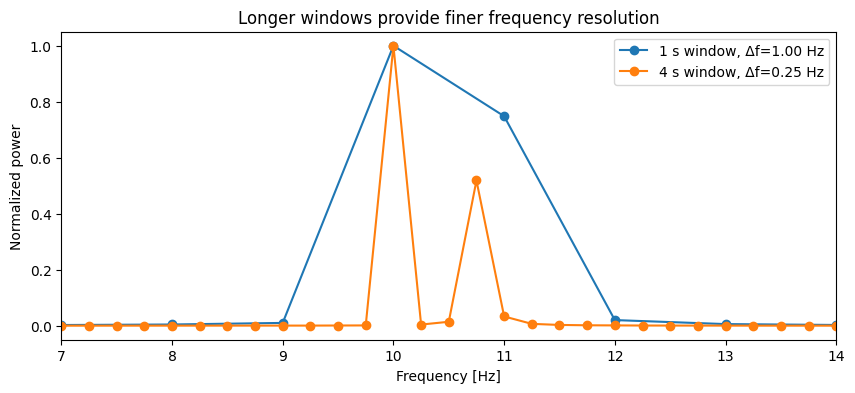

In [9]:
def two_tone_signal(duration_s, fs=FS):
    tt = np.arange(int(duration_s*fs)) / fs
    xx = np.sin(2*np.pi*10.0*tt) + 0.8*np.sin(2*np.pi*10.8*tt)
    return tt, xx

plt.figure(figsize=(10, 4))
for duration in [1.0, 4.0]:
    _, xx = two_tone_signal(duration)
    ff, pp = power_spectrum(xx)
    pp = pp / pp.max()
    plt.plot(ff, pp, marker="o", label=f"{duration:.0f} s window, Δf={FS/len(xx):.2f} Hz")
plt.xlim(7, 14)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Normalized power")
plt.title("Longer windows provide finer frequency resolution")
plt.legend()
plt.show()


At 1 s the bin spacing is 1 Hz, so the two nearby tones are difficult to distinguish. At 4 s the spacing is 0.25 Hz and the two components are much better resolved.

## 5. Band power and relative band power

In [10]:
BANDS = {"low": (0, 15), "mid": (15, 30), "high": (30, 50)}

def band_power(x, f_low, f_high, fs=FS, relative=False):
    freq, power = power_spectrum(x, fs)
    mask = (freq >= f_low) & (freq < f_high)
    bp = power[mask].sum()
    if relative:
        bp = bp / (power.sum() + 1e-12)
    return bp

for name, (lo, hi) in BANDS.items():
    print(name, "normal =", round(band_power(normal, lo, hi, relative=True), 4),
          "fault-like =", round(band_power(fault, lo, hi, relative=True), 4))


low normal = 0.9504 fault-like = 0.796
mid normal = 0.0274 fault-like = 0.1101
high normal = 0.0222 fault-like = 0.0939


The mid/high bands typically increase in the synthetic fault-like condition because the generator intentionally strengthens harmonics and high-frequency content.

## 6. Spectral leakage and Hann window

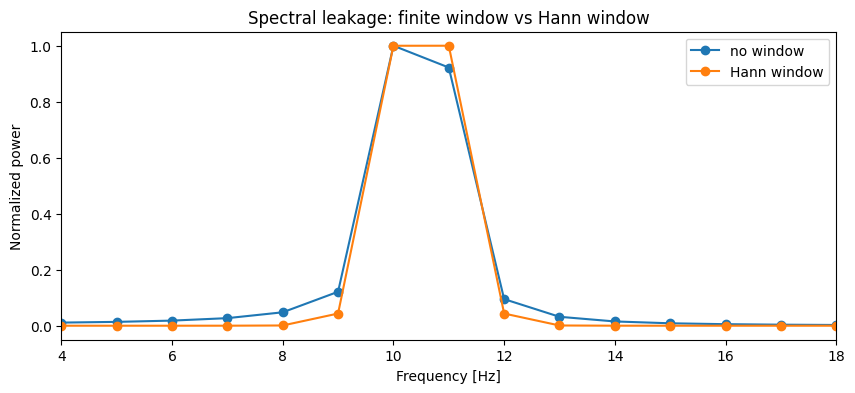

In [11]:
tt = np.arange(int(FS)) / FS
leak_signal = np.sin(2*np.pi*10.5*tt)
freq_raw, power_raw = power_spectrum(leak_signal, apply_hann=False)
freq_hann, power_hann = power_spectrum(leak_signal, apply_hann=True)
power_raw = power_raw / power_raw.max()
power_hann = power_hann / power_hann.max()

plt.figure(figsize=(10, 4))
plt.plot(freq_raw, power_raw, marker="o", label="no window")
plt.plot(freq_hann, power_hann, marker="o", label="Hann window")
plt.xlim(4, 18)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Normalized power")
plt.title("Spectral leakage: finite window vs Hann window")
plt.legend()
plt.show()


The Hann window suppresses distant sidelobes/leakage. The main lobe becomes broader, so very closely spaced frequencies can become slightly harder to separate.

## 7. Build a combined feature table

In [12]:
def rms(x):
    return np.sqrt(np.mean(np.asarray(x)**2))

def extract_features(x):
    return {
        "mean": np.mean(x),
        "std": np.std(x),
        "rms": rms(x),
        "max_abs": np.max(np.abs(x)),
        "dominant_freq": dominant_frequency(x),
        "rel_low": band_power(x, 0, 15, relative=True),
        "rel_mid": band_power(x, 15, 30, relative=True),
        "rel_high": band_power(x, 30, 50, relative=True),
    }

rows = []
for r in records:
    row = extract_features(r["signal"])
    row["condition"] = r["condition"]
    row["window_id"] = r["window_id"]
    rows.append(row)
features = pd.DataFrame(rows)
features.head()


,mean,std,rms,max_abs,dominant_freq,rel_low,rel_mid,rel_high,condition,window_id
0,0.096256,0.737823,0.744076,1.496522,10.0,0.950420,0.027387,0.022175,normal,normal_00
1,0.165598,0.667314,0.687554,1.426999,10.0,0.930445,0.039609,0.027371,normal,normal_01
2,0.145452,0.763477,0.777209,1.587607,10.0,0.942003,0.033645,0.022364,normal,normal_02
3,0.235633,0.726325,0.763591,1.744235,10.0,0.934428,0.030709,0.034729,normal,normal_03
4,0.097377,0.698091,0.704850,1.472160,9.5,0.934228,0.034908,0.030729,normal,normal_04


In [13]:
features.groupby("condition").mean(numeric_only=True).round(3)


,mean,std,rms,max_abs,dominant_freq,rel_low,rel_mid,rel_high
condition,,,,,,,,
fault-like,0.145,0.824,0.838,1.981,9.958,0.765,0.153,0.081
normal,0.148,0.742,0.757,1.569,9.971,0.941,0.032,0.026


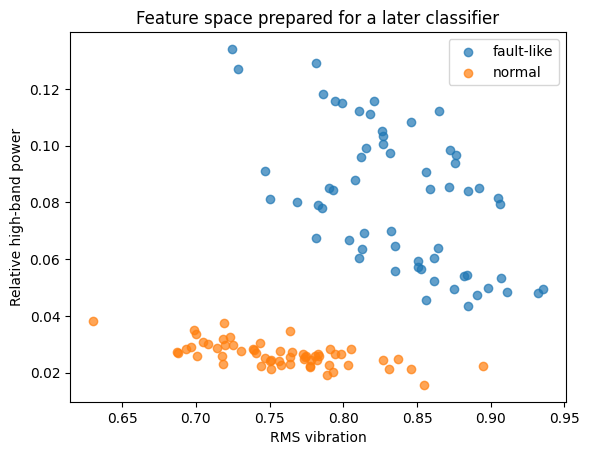

In [14]:
for condition, group in features.groupby("condition"):
    plt.scatter(group["rms"], group["rel_high"], label=condition, alpha=0.7)
plt.xlabel("RMS vibration")
plt.ylabel("Relative high-band power")
plt.title("Feature space prepared for a later classifier")
plt.legend()
plt.show()


## 8. Engineering interpretation — suggested answers

1. **Most discriminative features:** in this synthetic dataset, relative mid/high-band power is particularly informative; RMS also changes somewhat.
2. **Why relative power can transfer better:** dividing by total spectral power reduces sensitivity to overall amplitude scaling.
3. **Why remove the mean:** a non-zero mean produces a strong 0 Hz (DC) component that can dominate the spectrum.
4. **Longer windows:** they reduce Δf and improve frequency discrimination, but they summarize a longer period and therefore localize changes less precisely in time.
5. **Information lost by manual features:** exact within-window ordering, precise event timing and complex sequences of motifs can disappear when a waveform is compressed into a few statistics.


## Optional challenge — aliasing

Fs = 60.0 Hz; Nyquist = 30.0 Hz
35 Hz appears at approximately 25.0 Hz after sampling


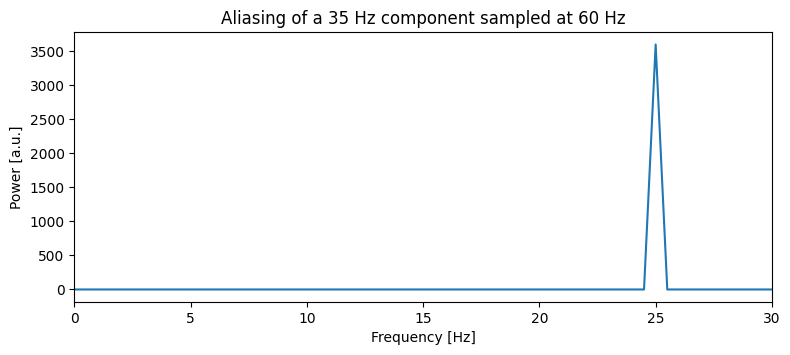

In [15]:
fs_alias = 60.0
tt = np.arange(int(2*fs_alias)) / fs_alias
x35 = np.sin(2*np.pi*35.0*tt)
ff, pp = power_spectrum(x35, fs=fs_alias)
peak = ff[1 + np.argmax(pp[1:])]
print("Fs =", fs_alias, "Hz; Nyquist =", fs_alias/2, "Hz")
print("35 Hz appears at approximately", peak, "Hz after sampling")

plt.figure(figsize=(9, 3.5))
plt.plot(ff, pp)
plt.xlim(0, fs_alias/2)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [a.u.]")
plt.title("Aliasing of a 35 Hz component sampled at 60 Hz")
plt.show()


A 35 Hz sinusoid sampled at 60 Hz aliases to approximately 25 Hz because it lies 5 Hz above the 30 Hz Nyquist limit.

## Take-away

The lab deliberately stops at **feature construction and interpretation**. A later lab can take this feature table and compare conventional regression/classification algorithms. This mirrors the lecture transition from manually designed temporal representations to supervised models and, later, learned representations.
